<a href="https://colab.research.google.com/github/anujjakhotiya/AI-DL_2026/blob/main/2403a51016_Labexam2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu


100%|██████████| 26.4M/26.4M [00:01<00:00, 23.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 348kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.24MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.5MB/s]


Training images: 60000
Testing images: 10000
Number of classes: 10


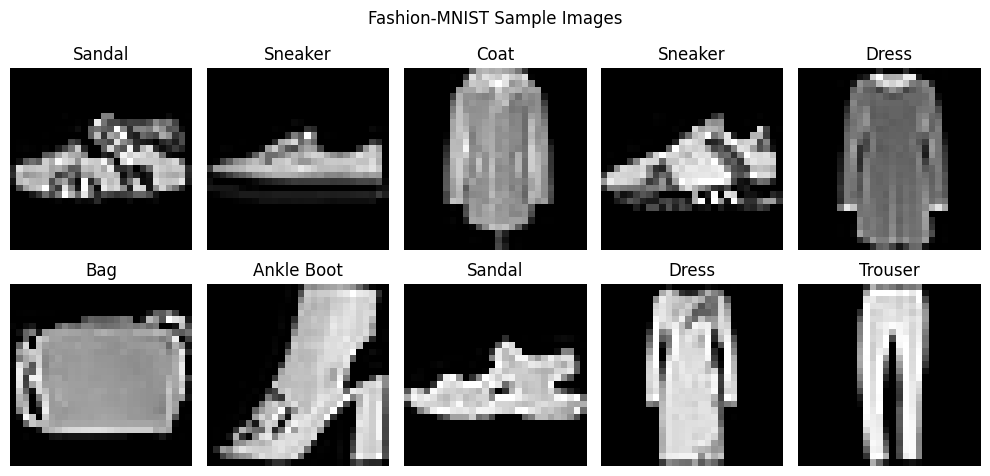

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Epoch [1/3] Loss: 0.4878 Accuracy: 82.44%
Epoch [2/3] Loss: 0.3117 Accuracy: 88.86%
Epoch [3/3] Loss: 0.2623 Accuracy: 90.44%

Test Accuracy: 90.30%

Classification Report:

              precision    recall  f1-score   support

     T-shirt       0.77      0.93      0.84      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.89      0.83      0.86      1000
       Dre

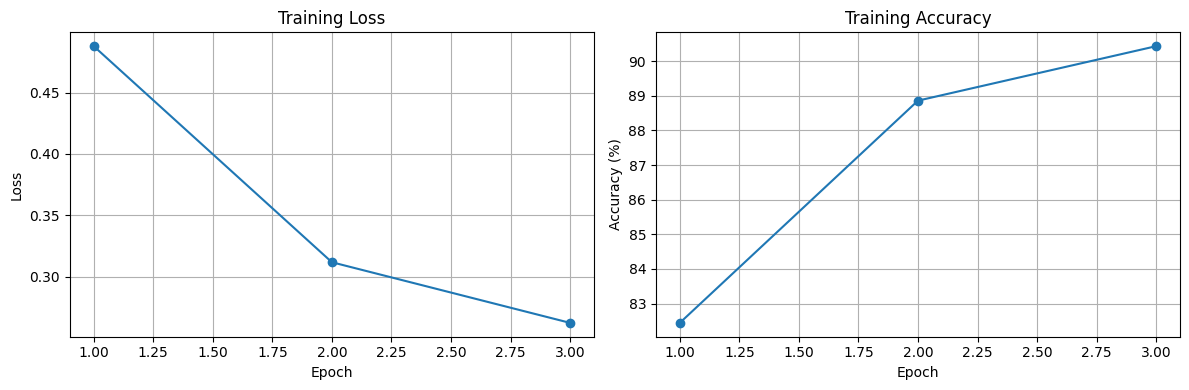

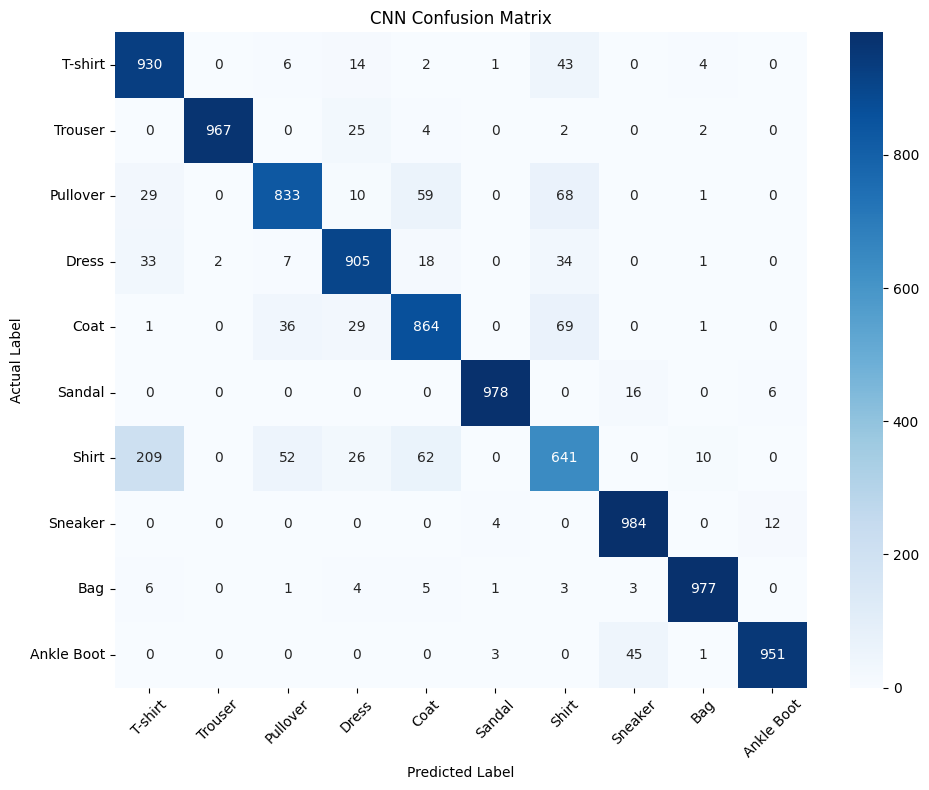

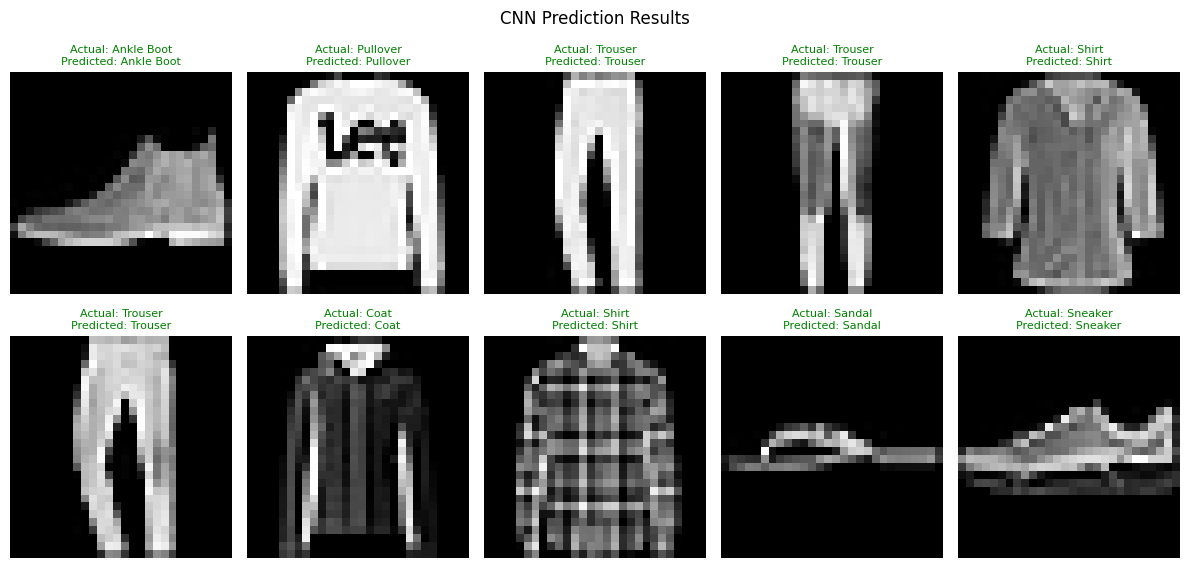

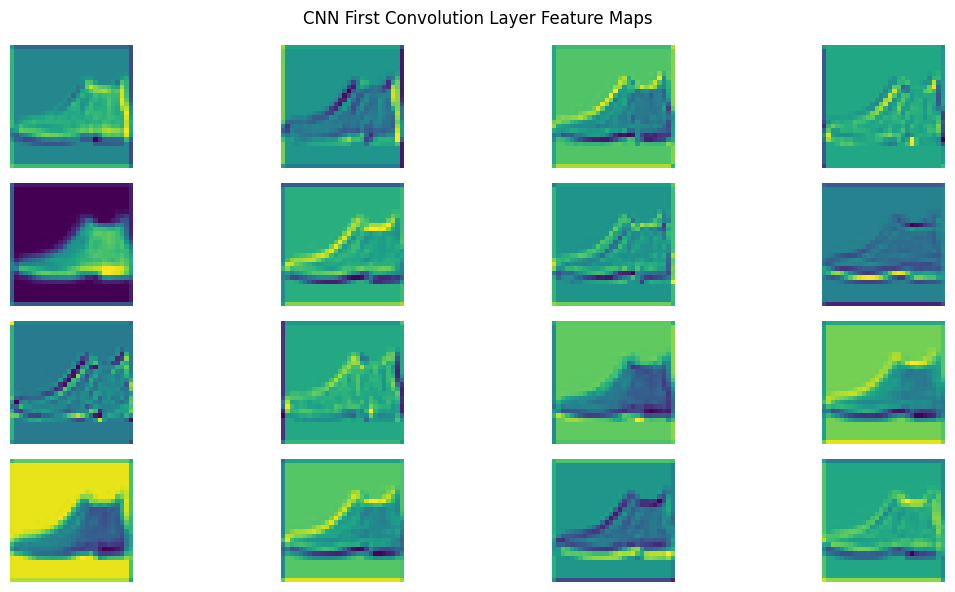


Model saved successfully!

Final Test Accuracy: 90.30%

Experiment completed successfully!


In [1]:
# 1. Import required libraries

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# 2. Download and preprocess Fashion-MNIST dataset

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

classes = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle Boot"
]

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", len(classes))


# 3. Visualize sample dataset images

images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(classes[labels[i]])
    plt.axis("off")

plt.suptitle("Fashion-MNIST Sample Images")
plt.tight_layout()
plt.show()


# 4. Implement CNN architecture

class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()

        self.dropout = nn.Dropout(0.3)

        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu3(x)

        x = self.dropout(x)

        x = self.fc2(x)

        return x


model = CNN().to(device)

print(model)


# 5. Define loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 3

train_losses = []
train_accuracies = []


# 6. Train the CNN model

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )


# 7. Evaluate the CNN model

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print("\nTest Accuracy:", f"{test_accuracy * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    zero_division=0
))


# 8. Visualize training loss and accuracy

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o"
)

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    marker="o"
)

plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid()

plt.tight_layout()
plt.show()


# 9. Confusion matrix

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# 10. Visualize sample predictions

model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images.to(device))
    _, predictions = torch.max(outputs, 1)

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].squeeze(), cmap="gray")

    actual = classes[labels[i].item()]
    predicted = classes[predictions[i].item()]

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color,
        fontsize=8
    )

    plt.axis("off")

plt.suptitle("CNN Prediction Results")
plt.tight_layout()
plt.show()


# 11. Visualize CNN feature maps

model.eval()

sample_image = images[0].unsqueeze(0).to(device)

with torch.no_grad():
    feature_maps = model.conv1(sample_image)

plt.figure(figsize=(12, 6))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    plt.imshow(
        feature_maps[0, i].cpu().numpy(),
        cmap="viridis"
    )

    plt.axis("off")

plt.suptitle("CNN First Convolution Layer Feature Maps")
plt.tight_layout()
plt.show()


# 12. Save trained model

torch.save(
    model.state_dict(),
    "FashionMNIST_CNN_Model.pth"
)

print("\nModel saved successfully!")

print("\nFinal Test Accuracy:",
      f"{test_accuracy * 100:.2f}%")

print("\nExperiment completed successfully!")